<a href="https://colab.research.google.com/github/miriamamin1213-ux/Ablation_studies/blob/main/HancockCNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Using device: cpu
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Eligible patients: 332
Class counts:
HPV_Label
0    191
1    141
Name: count, dtype: int64

Running 3-fold stratified CV on the entire eligible dataset.

FOLD 1/3
Fold 1 | Epoch 1/500 | Train loss=0.6955 | Val loss=0.6942 | ROC-AUC=0.4225 | PR-AUC=0.3744 | Balanced accuracy=0.5000
Fold 1 | Epoch 25/500 | Train loss=0.6672 | Val loss=0.6723 | ROC-AUC=0.7264 | PR-AUC=0.6975 | Balanced accuracy=0.6935
Fold 1 | Epoch 50/500 | Train loss=0.6040 | Val loss=0.6256 | ROC-AUC=0.7420 | PR-AUC=0.7096 | Balanced accuracy=0.6985
Fold 1 | Epoch 75/500 | Train loss=0.5531 | Val loss=0.5943 | ROC-AUC=0.7606 | PR-AUC=0.7313 | Balanced accuracy=0.7119
Fold 1 | Epoch 100/500 | Train loss=0.5218 | Val loss=0.5844 | ROC-AUC=0.7636 | PR-AUC=0.7257 | Balanced accuracy=0.7352
Fold 1 | Epoch 125/500 | Train loss=0.4900 | Val loss=0.5848 | ROC-AUC=0.7560 | PR-AUC=0.7

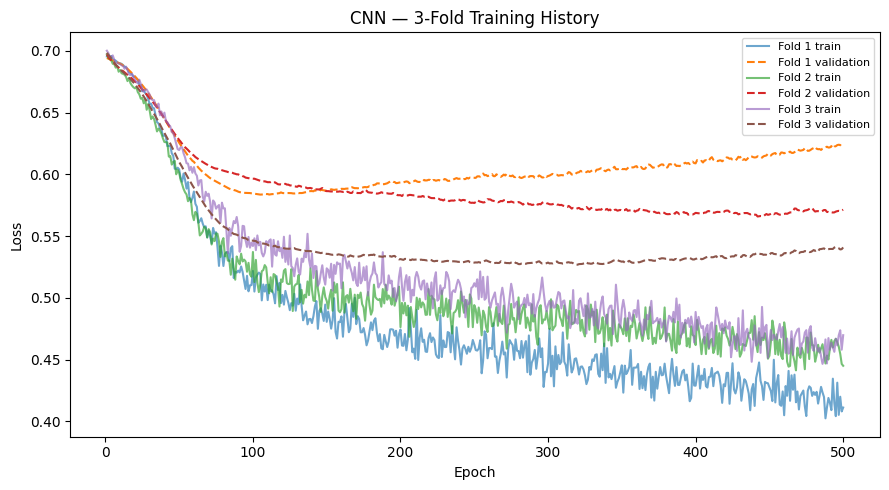


3-FOLD MEAN VALIDATION METRICS
                Checkpoint  Fold  Checkpoint_Epoch  Validation_Loss  ROC_AUC   PR_AUC  Threshold  Accuracy  Balanced_Accuracy  Precision   Recall       F1
best_val_balanced_accuracy   2.0         50.000000         0.636361 0.771625 0.699294   0.475000  0.753126           0.755044   0.700587 0.765957 0.725573
             best_val_loss   2.0        289.000000         0.558785 0.770963 0.755099   0.488333  0.735026           0.732991   0.710719 0.716312 0.693015
           best_val_pr_auc   2.0        188.000000         0.566527 0.778022 0.763449   0.548333  0.738002           0.724292   0.741405 0.631206 0.667567
          best_val_roc_auc   2.0        153.333333         0.600304 0.788810 0.759597   0.458333  0.741087           0.742785   0.692994 0.751773 0.711638

3-FOLD STANDARD DEVIATION
                Checkpoint  Fold  Checkpoint_Epoch  Validation_Loss  ROC_AUC   PR_AUC  Threshold  Accuracy  Balanced_Accuracy  Precision   Recall       F1
best_val_ba

  0%|          | 0/111 [00:00<?, ?it/s]

  0%|          | 0/111 [00:00<?, ?it/s]

  0%|          | 0/110 [00:00<?, ?it/s]

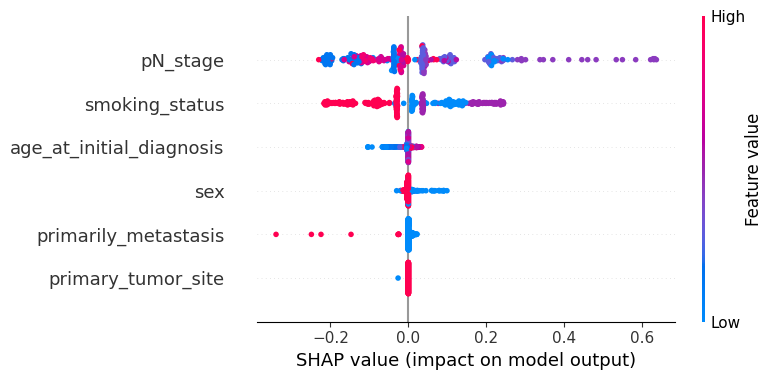


Combined SHAP importance across folds:
                 Feature  Mean_Absolute_SHAP
                pN_stage            0.122572
          smoking_status            0.102208
age_at_initial_diagnosis            0.010052
                     sex            0.008270
    primarily_metastasis            0.006029
      primary_tumor_site            0.000079


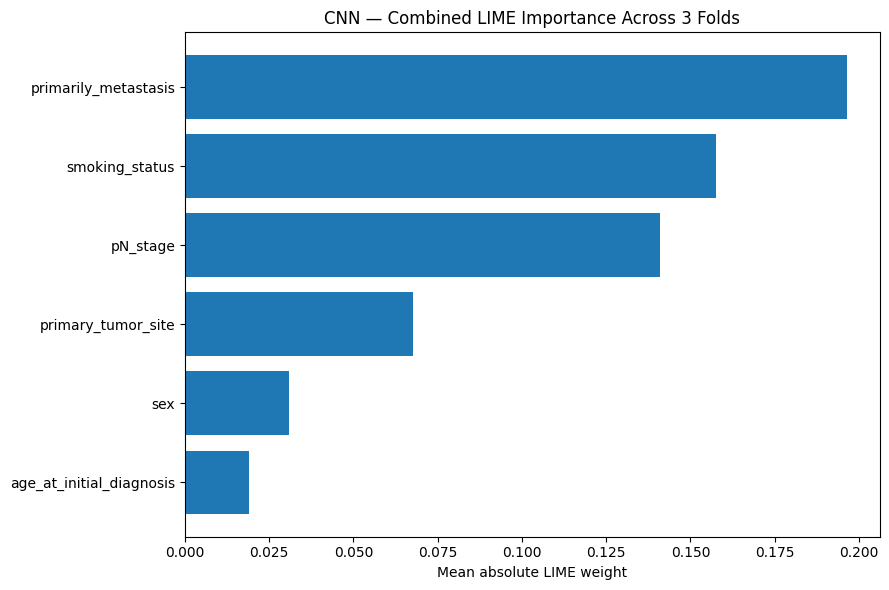


Combined LIME importance across folds:
                 Feature  Mean_Absolute_LIME
    primarily_metastasis            0.196406
          smoking_status            0.157493
                pN_stage            0.141046
      primary_tumor_site            0.067633
                     sex            0.030891
age_at_initial_diagnosis            0.019064


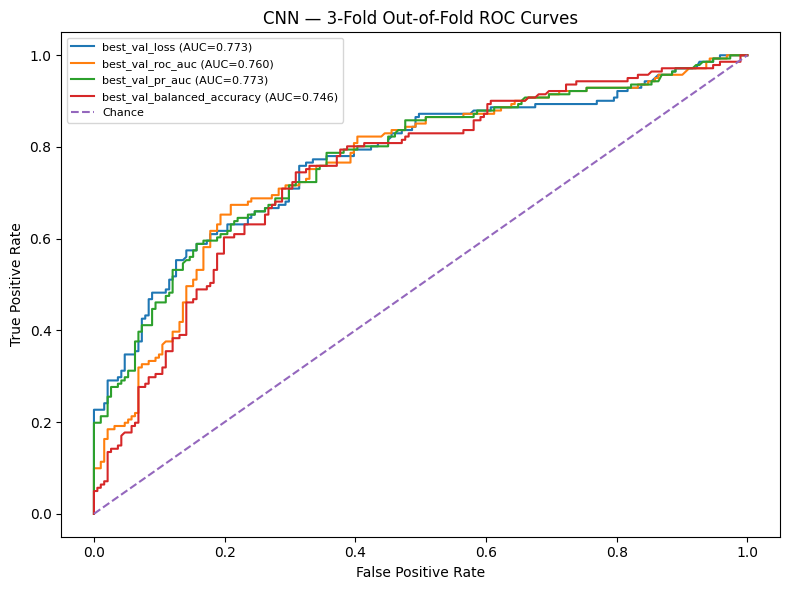

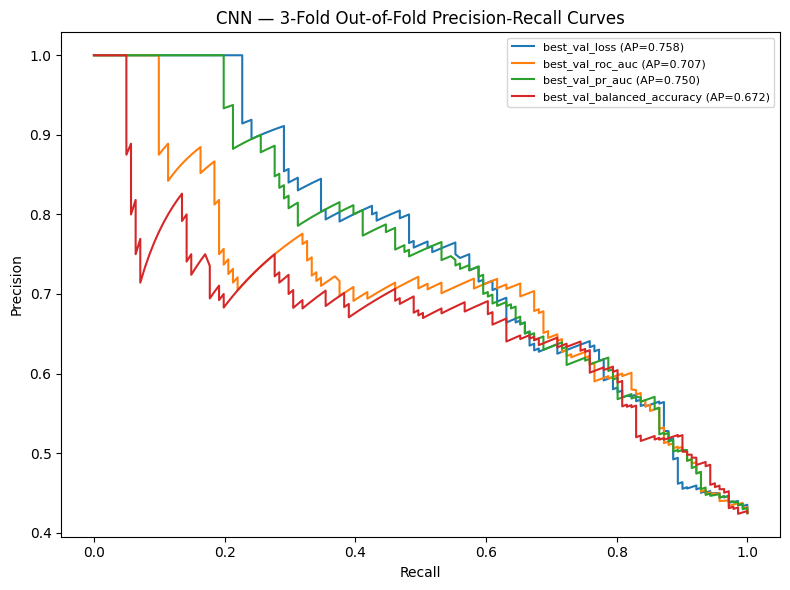


CNN — 3-FOLD VALIDATION CHECKPOINT COMPARISON
                Checkpoint  Checkpoint_Epoch  Threshold  Accuracy  Balanced_Accuracy  Precision   Recall       F1  ROC_AUC   PR_AUC
best_val_balanced_accuracy         50.000000   0.475000  0.753126           0.755044   0.700587 0.765957 0.725573 0.771625 0.699294
             best_val_loss        289.000000   0.488333  0.735026           0.732991   0.710719 0.716312 0.693015 0.770963 0.755099
           best_val_pr_auc        188.000000   0.548333  0.738002           0.724292   0.741405 0.631206 0.667567 0.778022 0.763449
          best_val_roc_auc        153.333333   0.458333  0.741087           0.742785   0.692994 0.751773 0.711638 0.788810 0.759597

Per-fold standard deviations:
                Checkpoint  Checkpoint_Epoch  Threshold  Accuracy  Balanced_Accuracy  Precision   Recall       F1  ROC_AUC   PR_AUC
best_val_balanced_accuracy         41.218928   0.036056  0.035402           0.020939   0.088823 0.076714 0.010018 0.046957 0.10702

In [3]:


# ============================================================
# CNN — HANCOCK HPV CLASSIFIER
# GPT-2-aligned data preparation | Seed 42 | No SMOTE
# Full 500 epochs | Four validation-selected checkpoints
# ============================================================

import os
import json
import random
import copy
import warnings
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import importlib.util
import subprocess
import sys

if importlib.util.find_spec('lime') is None or importlib.util.find_spec('shap') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'lime', 'shap'])

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from google.colab import drive

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
MAX_EPOCHS = 500
BATCH_SIZE = 32

# ------------------------------------------------------------
# REPRODUCIBILITY AND DEVICE
# ------------------------------------------------------------

def seed_everything(seed=42):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

drive.mount("/content/drive")


# ============================================================
# 1. LOAD AND PREPARE DATA
# ============================================================

BASE = "/content/drive/MyDrive"
OUT_DIR = os.path.join(BASE, "CNN_results")
CHECKPOINT_DIR = os.path.join(OUT_DIR, "checkpoints")

os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(CHECKPOINT_DIR, exist_ok=True)


def load_json_table(path):
    with open(path, "r", encoding="utf-8") as f:
        obj = json.load(f)

    if isinstance(obj, list):
        return pd.DataFrame(obj)

    if isinstance(obj, dict):
        for key in ["data", "records", "patients", "items"]:
            if key in obj and isinstance(obj[key], list):
                return pd.DataFrame(obj[key])

        return pd.DataFrame(obj)

    raise ValueError(f"Cannot read table from {path}")


clinical = load_json_table(
    os.path.join(BASE, "clinical_data.json")
)

pathology = load_json_table(
    os.path.join(BASE, "pathological_data.json")
)

if "patient_id" not in clinical.columns:
    raise KeyError("clinical_data.json must contain patient_id.")

if "patient_id" not in pathology.columns:
    raise KeyError("pathological_data.json must contain patient_id.")

# Same left join and suffixes as GPT-2.
df = clinical.merge(
    pathology,
    on="patient_id",
    how="left",
    suffixes=("", "_path")
)

# Same target priority as GPT-2.
target_candidates = [
    "hpv_association_p16",
    "hpv_association_p16_path"
]

target_col = next(
    (c for c in target_candidates if c in df.columns),
    None
)

if target_col is None:
    raise KeyError(
        "HPV target column not found. Checked: "
        f"{target_candidates}"
    )


# Same predictor set and fallback approach as GPT-2.
feature_candidates = {
    "age_at_initial_diagnosis": [
        "age_at_initial_diagnosis"
    ],
    "sex": [
        "sex"
    ],
    "smoking_status": [
        "smoking_status"
    ],
    "primary_tumor_site": [
        "primary_tumor_site"
    ],
    "primarily_metastasis": [
        "primarily_metastasis"
    ],
    "pN_stage": [
        "pN_stage",
        "pN_stage_path",
        "pathological_N_stage",
        "pathological_n_stage"
    ]
}

rename_map = {}

for feature_name, candidates in feature_candidates.items():
    match = next(
        (col for col in candidates if col in df.columns),
        None
    )

    if match is None:
        raise KeyError(
            f"Missing predictor '{feature_name}'. "
            f"Checked columns: {candidates}"
        )

    if match != feature_name:
        rename_map[match] = feature_name

df = df.rename(columns=rename_map)
features = list(feature_candidates.keys())


# ------------------------------------------------------------
# NORMALIZE TARGET LABEL
# ------------------------------------------------------------

def normalize_label(value):
    if pd.isna(value):
        return np.nan

    value = str(value).strip().lower()

    if value in {"negative", "neg", "0", "false", "no"}:
        return 0

    if value in {"positive", "pos", "1", "true", "yes"}:
        return 1

    try:
        number = float(value)

        if number in (0.0, 1.0):
            return int(number)

    except (ValueError, TypeError):
        pass

    return np.nan


df["HPV_Label"] = df[target_col].map(normalize_label)

df = df.dropna(subset=["HPV_Label"]).copy()
df["HPV_Label"] = df["HPV_Label"].astype(int)

df = df[
    ["patient_id"] + features + ["HPV_Label"]
].copy()



# ============================================================
# 2. STRATIFIED 3-FOLD CROSS-VALIDATION — ENTIRE DATASET
# ============================================================

from sklearn.model_selection import StratifiedKFold
from lime.lime_tabular import LimeTabularExplainer
from collections import defaultdict
import shap

N_SPLITS = 3
skf = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=SEED
)

thresholds = np.linspace(0.10, 0.90, 161)
numeric_features = ["age_at_initial_diagnosis"]
categorical_features = [c for c in features if c not in numeric_features]

checkpoint_specs = {
    "best_val_loss": {"filename": "cnn_best_val_loss.pt"},
    "best_val_roc_auc": {"filename": "cnn_best_val_roc_auc.pt"},
    "best_val_pr_auc": {"filename": "cnn_best_val_pr_auc.pt"},
    "best_val_balanced_accuracy": {
        "filename": "cnn_best_val_balanced_accuracy.pt"
    }
}

all_metrics = []
all_predictions = []
all_histories = []
fold_runs = []

print("Eligible patients:", len(df))
print("Class counts:")
print(df["HPV_Label"].value_counts().sort_index())
print(f"\nRunning {N_SPLITS}-fold stratified CV on the entire eligible dataset.")


# ============================================================
# 3. ORIGINAL CNN ARCHITECTURE AND VALIDATION HELPERS
# ============================================================

class CNNClassifier(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.conv = nn.Conv1d(
            in_channels=1,
            out_channels=16,
            kernel_size=3,
            padding=1
        )
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.25)
        self.fc1 = nn.Linear(input_dim * 16, 32)
        self.fc2 = nn.Linear(32, 16)
        self.fc3 = nn.Linear(16, 2)

    def forward(self, x):
        x = x.unsqueeze(1)
        x = self.conv(x)
        x = self.relu(x)
        x = self.dropout(x)
        x = x.flatten(start_dim=1)
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        x = self.relu(x)
        return self.fc3(x)


def select_threshold(y_true, probabilities):
    scores = [
        balanced_accuracy_score(
            y_true,
            (probabilities >= threshold).astype(int)
        )
        for threshold in thresholds
    ]
    best_score = max(scores)
    best_threshold = min(
        (
            threshold
            for threshold, score in zip(thresholds, scores)
            if np.isclose(score, best_score)
        ),
        key=lambda threshold: abs(threshold - 0.5)
    )
    return float(best_threshold), float(best_score)


def predict_probabilities(model, X):
    model.eval()
    X_tensor = torch.as_tensor(
        X, dtype=torch.float32, device=device
    )
    with torch.no_grad():
        return torch.softmax(model(X_tensor), dim=1)[:, 1].cpu().numpy()


def load_checkpoint(path):
    try:
        return torch.load(
            path, map_location=device, weights_only=False
        )
    except TypeError:
        return torch.load(path, map_location=device)


# ============================================================
# 4. THREE-FOLD TRAINING — ORIGINAL PREPROCESSING AND CNN
# ============================================================

for fold, (train_idx, val_idx) in enumerate(
    skf.split(df[features], df["HPV_Label"]), start=1
):
    print("\n" + "=" * 65)
    print(f"FOLD {fold}/{N_SPLITS}")
    print("=" * 65)

    seed_everything(SEED)

    train = df.iloc[train_idx].reset_index(drop=True)
    val = df.iloc[val_idx].reset_index(drop=True)

    X_train_df = train[features].copy()
    X_val_df = val[features].copy()

    # Fit all imputation and preprocessing steps on this fold's
    # training partition only.
    for frame in (X_train_df, X_val_df):
        frame["age_at_initial_diagnosis"] = pd.to_numeric(
            frame["age_at_initial_diagnosis"], errors="coerce"
        )

    age_median = X_train_df["age_at_initial_diagnosis"].median()
    if pd.isna(age_median):
        age_median = 0.0

    for frame in (X_train_df, X_val_df):
        frame["age_at_initial_diagnosis"] = (
            frame["age_at_initial_diagnosis"].fillna(age_median)
        )

    for col in categorical_features:
        for frame in (X_train_df, X_val_df):
            frame[col] = (
                frame[col].astype("object")
                .replace(r"^\s*$", np.nan, regex=True)
                .replace(["nan", "None", "NaN"], np.nan)
            )

        modes = X_train_df[col].mode(dropna=True)
        fill_value = str(modes.iloc[0]) if not modes.empty else "Unknown"

        for frame in (X_train_df, X_val_df):
            frame[col] = (
                frame[col].fillna(fill_value).astype(str)
                .replace(["", "nan", "None", "NaN"], "Unknown")
            )

    try:
        encoder = OneHotEncoder(
            handle_unknown="ignore", sparse_output=False
        )
    except TypeError:
        encoder = OneHotEncoder(
            handle_unknown="ignore", sparse=False
        )

    preprocessor = ColumnTransformer([
        ("num", StandardScaler(), numeric_features),
        ("cat", encoder, categorical_features)
    ])

    X_train = preprocessor.fit_transform(X_train_df).astype(np.float32)
    X_val = preprocessor.transform(X_val_df).astype(np.float32)
    y_train = train["HPV_Label"].to_numpy().astype(np.int64)
    y_val = val["HPV_Label"].to_numpy().astype(np.int64)

    counts = np.bincount(y_train, minlength=2)
    if np.any(counts == 0):
        raise ValueError(
            f"Both classes must be present in fold {fold} training data."
        )

    weights = len(y_train) / (2.0 * counts)
    class_weights = torch.tensor(
        weights, dtype=torch.float32, device=device
    )

    train_dataset = TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(y_train, dtype=torch.long)
    )
    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=torch.Generator().manual_seed(SEED)
    )

    X_val_t = torch.tensor(
        X_val, dtype=torch.float32, device=device
    )
    y_val_t = torch.tensor(
        y_val, dtype=torch.long, device=device
    )

    model = CNNClassifier(input_dim=X_train.shape[1]).to(device)

    criterion = nn.CrossEntropyLoss(
        weight=class_weights,
        reduction="none"
    )
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.0001,
        weight_decay=1e-4
    )

    best_values = {
        "best_val_loss": float("inf"),
        "best_val_roc_auc": -float("inf"),
        "best_val_pr_auc": -float("inf"),
        "best_val_balanced_accuracy": -float("inf")
    }
    best_epochs = {}
    history = []

    fold_dir = os.path.join(CHECKPOINT_DIR, f"fold_{fold}")
    os.makedirs(fold_dir, exist_ok=True)

    # ========================================================
    # 5. TRAIN ALL 500 EPOCHS — FOUR VALIDATION CHECKPOINTS
    # ========================================================

    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        running_loss = 0.0
        seen = 0

        for xb, yb in train_loader:
            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()
            per_example_loss = criterion(model(xb), yb)
            loss = per_example_loss.mean()
            loss.backward()
            optimizer.step()

            running_loss += per_example_loss.detach().sum().item()
            seen += len(yb)

        train_loss = running_loss / max(seen, 1)

        model.eval()
        with torch.no_grad():
            val_loss = criterion(model(X_val_t), y_val_t).mean().item()

        val_prob = predict_probabilities(model, X_val)
        val_threshold, val_balanced = select_threshold(y_val, val_prob)
        val_roc = (
            roc_auc_score(y_val, val_prob)
            if len(np.unique(y_val)) == 2 else np.nan
        )
        val_pr = average_precision_score(y_val, val_prob)

        val_results = {
            "probabilities": val_prob,
            "threshold": val_threshold,
            "balanced_accuracy": val_balanced,
            "roc_auc": float(val_roc),
            "pr_auc": float(val_pr)
        }

        history.append({
            "fold": fold,
            "epoch": epoch,
            "train_loss": float(train_loss),
            "val_loss": float(val_loss),
            "val_roc_auc": float(val_roc),
            "val_pr_auc": float(val_pr),
            "val_balanced_accuracy": float(val_balanced),
            "val_threshold": float(val_threshold)
        })

        scores = {
            "best_val_loss": val_loss,
            "best_val_roc_auc": val_roc,
            "best_val_pr_auc": val_pr,
            "best_val_balanced_accuracy": val_balanced
        }

        for name, score in scores.items():
            better = (
                score < best_values[name]
                if name == "best_val_loss"
                else np.isfinite(score) and score > best_values[name]
            )

            if better:
                best_values[name] = float(score)
                best_epochs[name] = epoch

                torch.save({
                    "model_state_dict": copy.deepcopy(model.state_dict()),
                    "epoch": int(epoch),
                    "validation_loss": float(val_loss),
                    "validation_roc_auc": float(val_roc),
                    "validation_pr_auc": float(val_pr),
                    "validation_balanced_accuracy": float(val_balanced),
                    "validation_threshold": float(val_threshold)
                }, os.path.join(
                    fold_dir, checkpoint_specs[name]["filename"]
                ))

        if epoch == 1 or epoch % 25 == 0:
            print(
                f"Fold {fold} | Epoch {epoch}/{MAX_EPOCHS} | "
                f"Train loss={train_loss:.4f} | "
                f"Val loss={val_loss:.4f} | "
                f"ROC-AUC={val_roc:.4f} | "
                f"PR-AUC={val_pr:.4f} | "
                f"Balanced accuracy={val_balanced:.4f}"
            )

    if len(history) != MAX_EPOCHS:
        raise RuntimeError(
            f"Fold {fold}: expected {MAX_EPOCHS} epochs."
        )

    all_histories.extend(history)
    print("Best checkpoint epochs:", best_epochs)

    # ========================================================
    # 6. VALIDATION EVALUATION — ALL FOUR CHECKPOINTS
    # ========================================================

    fold_explain_state = None

    for name, spec in checkpoint_specs.items():
        checkpoint_path = os.path.join(
            fold_dir, spec["filename"]
        )
        checkpoint = load_checkpoint(checkpoint_path)
        model.load_state_dict(checkpoint["model_state_dict"])

        val_prob = predict_probabilities(model, X_val)
        best_threshold, val_balanced = select_threshold(y_val, val_prob)
        val_pred = (val_prob >= best_threshold).astype(int)

        metrics = {
            "Fold": fold,
            "Checkpoint": name,
            "Checkpoint_Epoch": int(checkpoint["epoch"]),
            "Validation_Loss": float(checkpoint["validation_loss"]),
            "ROC_AUC": (
                roc_auc_score(y_val, val_prob)
                if len(np.unique(y_val)) == 2 else np.nan
            ),
            "PR_AUC": average_precision_score(y_val, val_prob),
            "Threshold": best_threshold,
            "Accuracy": accuracy_score(y_val, val_pred),
            "Balanced_Accuracy": balanced_accuracy_score(y_val, val_pred),
            "Precision": precision_score(
                y_val, val_pred, zero_division=0
            ),
            "Recall": recall_score(y_val, val_pred, zero_division=0),
            "F1": f1_score(y_val, val_pred, zero_division=0)
        }
        all_metrics.append(metrics)

        all_predictions.append(pd.DataFrame({
            "patient_id": val["patient_id"].to_numpy(),
            "y_true": y_val,
            "probability_positive": val_prob,
            "prediction": val_pred,
            "fold": fold,
            "checkpoint": name,
            "checkpoint_epoch": int(checkpoint["epoch"]),
            "threshold": best_threshold
        }))

        print(f"\nFold {fold} | {name} | Epoch {checkpoint['epoch']}")
        print(pd.Series(metrics).to_string())

        if name == "best_val_roc_auc":
            fold_explain_state = copy.deepcopy(
                checkpoint["model_state_dict"]
            )

    fold_runs.append({
        "fold": fold,
        "preprocessor": preprocessor,
        "X_train": X_train,
        "X_val": X_val,
        "X_train_df": X_train_df,
        "X_val_df": X_val_df,
        "y_train": y_train,
        "y_val": y_val,
        "model_state_dict": fold_explain_state,
        "fold_dir": fold_dir,
        "best_epochs": best_epochs,
        "class_weights": weights.tolist()
    })


# ============================================================
# 7. COMBINED 3-FOLD METRICS AND TRAINING HISTORY
# ============================================================

metrics_df = pd.DataFrame(all_metrics)
mean_metrics = (
    metrics_df.groupby("Checkpoint")
    .mean(numeric_only=True)
    .reset_index()
)
std_metrics = (
    metrics_df.groupby("Checkpoint")
    .std(numeric_only=True)
    .reset_index()
)

metrics_df.to_csv(
    os.path.join(OUT_DIR, "cnn_3fold_metrics_by_fold.csv"),
    index=False
)
mean_metrics.to_csv(
    os.path.join(OUT_DIR, "cnn_3fold_metrics_mean.csv"),
    index=False
)
std_metrics.to_csv(
    os.path.join(OUT_DIR, "cnn_3fold_metrics_std.csv"),
    index=False
)

predictions_df = pd.concat(all_predictions, ignore_index=True)
predictions_df.to_csv(
    os.path.join(OUT_DIR, "cnn_3fold_validation_predictions.csv"),
    index=False
)

history_df = pd.DataFrame(all_histories)
history_df.to_csv(
    os.path.join(OUT_DIR, "cnn_3fold_training_history.csv"),
    index=False
)

plt.figure(figsize=(9, 5))
for fold in range(1, N_SPLITS + 1):
    fold_history = history_df[history_df["fold"] == fold]
    plt.plot(
        fold_history["epoch"],
        fold_history["train_loss"],
        alpha=0.65,
        label=f"Fold {fold} train"
    )
    plt.plot(
        fold_history["epoch"],
        fold_history["val_loss"],
        linestyle="--",
        label=f"Fold {fold} validation"
    )
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN — 3-Fold Training History")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(
    os.path.join(OUT_DIR, "cnn_3fold_training_history.png"),
    dpi=150
)
plt.show()

print("\n3-FOLD MEAN VALIDATION METRICS")
print(mean_metrics.to_string(index=False))
print("\n3-FOLD STANDARD DEVIATION")
print(std_metrics.to_string(index=False))


# ============================================================
# 8. SHAP — COMBINED BEESWARM ACROSS ALL THREE FOLDS
# ============================================================

shap_values_all = []
shap_data_all = []

# Stable category codes are used only for displaying raw feature values.
display_category_maps = {
    col: {
        value: index
        for index, value in enumerate(
            sorted(df[col].fillna("Unknown").astype(str).unique())
        )
    }
    for col in categorical_features
}

for run in fold_runs:
    model = CNNClassifier(input_dim=run["X_train"].shape[1]).to(device)
    model.load_state_dict(run["model_state_dict"])
    model.eval()

    rng = np.random.default_rng(SEED + run["fold"])
    background = run["X_train"][
        rng.choice(
            len(run["X_train"]),
            min(30, len(run["X_train"])),
            replace=False
        )
    ]

    def shap_predict(values, model=model):
        return predict_probabilities(
            model, np.asarray(values, dtype=np.float32)
        )

    explainer = shap.KernelExplainer(shap_predict, background)
    raw_shap = explainer.shap_values(
        run["X_val"], nsamples=100
    )

    if isinstance(raw_shap, list):
        raw_shap = raw_shap[-1]

    raw_shap = np.asarray(raw_shap)
    if raw_shap.ndim == 3:
        raw_shap = raw_shap[:, :, -1]
    raw_shap = np.squeeze(raw_shap)

    if raw_shap.ndim == 1:
        raw_shap = raw_shap.reshape(1, -1)

    cat_encoder = run["preprocessor"].named_transformers_["cat"]
    feature_groups = [np.array([0])]
    start = 1

    for categories in cat_encoder.categories_:
        width = len(categories)
        feature_groups.append(np.arange(start, start + width))
        start += width

    grouped_shap = np.column_stack([
        raw_shap[:, indices].sum(axis=1)
        for indices in feature_groups
    ])
    shap_values_all.append(grouped_shap)

    display_data = pd.DataFrame()
    display_data[features[0]] = (
        run["X_val_df"][features[0]].to_numpy(dtype=float)
    )
    for col in categorical_features:
        display_data[col] = (
            run["X_val_df"][col].astype(str)
            .map(display_category_maps[col]).to_numpy(dtype=float)
        )
    shap_data_all.append(display_data[features])

combined_shap = np.vstack(shap_values_all)
combined_shap_data = pd.concat(shap_data_all, ignore_index=True)

plt.figure(figsize=(9, 6))
shap.summary_plot(
    combined_shap,
    combined_shap_data,
    feature_names=features,
    plot_type="dot",
    show=False
)
plt.tight_layout()
plt.savefig(
    os.path.join(OUT_DIR, "cnn_shap_beeswarm_3fold.png"),
    dpi=200,
    bbox_inches="tight"
)
plt.show()

shap_importance = pd.DataFrame({
    "Feature": features,
    "Mean_Absolute_SHAP": np.abs(combined_shap).mean(axis=0)
}).sort_values("Mean_Absolute_SHAP", ascending=False)

shap_importance.to_csv(
    os.path.join(OUT_DIR, "cnn_shap_importance_3fold.csv"),
    index=False
)
print("\nCombined SHAP importance across folds:")
print(shap_importance.to_string(index=False))


# ============================================================
# 9. LIME — MEAN ABSOLUTE EXPLANATIONS ACROSS ALL THREE FOLDS
# ============================================================

lime_weights = defaultdict(list)

for run in fold_runs:
    model = CNNClassifier(input_dim=run["X_train"].shape[1]).to(device)
    model.load_state_dict(run["model_state_dict"])
    model.eval()

    category_maps = {}
    category_names = {}

    lime_train = np.zeros(
        (len(run["X_train_df"]), len(features)), dtype=float
    )
    lime_val = np.zeros(
        (len(run["X_val_df"]), len(features)), dtype=float
    )

    lime_train[:, 0] = run["X_train_df"][features[0]].to_numpy(dtype=float)
    lime_val[:, 0] = run["X_val_df"][features[0]].to_numpy(dtype=float)

    for j, feature in enumerate(categorical_features, start=1):
        categories = sorted(
            run["X_train_df"][feature].astype(str).unique().tolist()
        )
        category_maps[feature] = {
            value: index for index, value in enumerate(categories)
        }
        category_names[j] = categories
        lime_train[:, j] = (
            run["X_train_df"][feature]
            .astype(str).map(category_maps[feature]).to_numpy(dtype=float)
        )
        lime_val[:, j] = (
            run["X_val_df"][feature].astype(str)
            .map(lambda value: category_maps[feature].get(value, 0))
            .to_numpy(dtype=float)
        )

    categorical_indices = list(range(1, len(features)))

    explainer = LimeTabularExplainer(
        lime_train,
        feature_names=features,
        class_names=["HPV negative", "HPV positive"],
        categorical_features=categorical_indices,
        categorical_names=category_names,
        mode="classification",
        discretize_continuous=True,
        random_state=SEED
    )

    def lime_predict(values, run=run, model=model,
                     category_maps=category_maps):
        decoded = pd.DataFrame(
            np.asarray(values), columns=features
        )
        decoded[features[0]] = pd.to_numeric(
            decoded[features[0]], errors="coerce"
        ).fillna(
            run["X_train_df"][features[0]].median()
        )

        for j, feature in enumerate(categorical_features, start=1):
            categories = list(category_maps[feature].keys())
            codes = decoded.iloc[:, j].round().astype(int)
            decoded[feature] = codes.map(
                lambda code: (
                    categories[code]
                    if 0 <= code < len(categories)
                    else categories[0]
                )
            )

        transformed = run["preprocessor"].transform(
            decoded[features]
        ).astype(np.float32)
        positive = predict_probabilities(model, transformed)
        return np.column_stack([1 - positive, positive])

    for row in lime_val:
        explanation = explainer.explain_instance(
            row,
            lime_predict,
            labels=(1,),
            num_features=len(features),
            num_samples=1000
        )

        # Aggregate using feature indices, not fragile text matching.
        feature_weights = dict(explanation.as_map().get(1, []))
        for feature_index, feature in enumerate(features):
            lime_weights[feature].append(
                abs(feature_weights.get(feature_index, 0.0))
            )

lime_importance = pd.DataFrame({
    "Feature": features,
    "Mean_Absolute_LIME": [
        np.mean(lime_weights[feature]) for feature in features
    ]
}).sort_values("Mean_Absolute_LIME", ascending=False)

lime_importance.to_csv(
    os.path.join(OUT_DIR, "cnn_lime_importance_3fold.csv"),
    index=False
)

plt.figure(figsize=(9, 6))
plt.barh(
    lime_importance["Feature"][::-1],
    lime_importance["Mean_Absolute_LIME"][::-1]
)
plt.xlabel("Mean absolute LIME weight")
plt.title("CNN — Combined LIME Importance Across 3 Folds")
plt.tight_layout()
plt.savefig(
    os.path.join(OUT_DIR, "cnn_lime_importance_3fold.png"),
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("\nCombined LIME importance across folds:")
print(lime_importance.to_string(index=False))


# ============================================================
# 10. COMBINED OUT-OF-FOLD ROC AND PRECISION-RECALL CURVES
# ============================================================

# Every patient contributes one out-of-fold prediction per checkpoint.
# These plots replace the original single-test-set curves.

plt.figure(figsize=(8, 6))
for checkpoint_name in checkpoint_specs:
    subset = predictions_df[
        predictions_df["checkpoint"] == checkpoint_name
    ]
    fpr, tpr, _ = roc_curve(
        subset["y_true"], subset["probability_positive"]
    )
    auc_value = roc_auc_score(
        subset["y_true"], subset["probability_positive"]
    )
    plt.plot(
        fpr, tpr,
        label=f"{checkpoint_name} (AUC={auc_value:.3f})"
    )

plt.plot([0, 1], [0, 1], "--", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("CNN — 3-Fold Out-of-Fold ROC Curves")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(
    os.path.join(OUT_DIR, "roc_curves_all_checkpoints_3fold.png"),
    dpi=150
)
plt.show()

plt.figure(figsize=(8, 6))
for checkpoint_name in checkpoint_specs:
    subset = predictions_df[
        predictions_df["checkpoint"] == checkpoint_name
    ]
    precision, recall, _ = precision_recall_curve(
        subset["y_true"], subset["probability_positive"]
    )
    ap_value = average_precision_score(
        subset["y_true"], subset["probability_positive"]
    )
    plt.plot(
        recall, precision,
        label=f"{checkpoint_name} (AP={ap_value:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("CNN — 3-Fold Out-of-Fold Precision-Recall Curves")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(
    os.path.join(OUT_DIR, "pr_curves_all_checkpoints_3fold.png"),
    dpi=150
)
plt.show()


# ============================================================
# 11. SAVE FOLD PREPROCESSORS AND SETTINGS
# ============================================================

for run in fold_runs:
    joblib.dump(
        run["preprocessor"],
        os.path.join(
            OUT_DIR, f"cnn_preprocessor_fold_{run['fold']}.joblib"
        )
    )

settings = {
    "model": "CNN",
    "seed": SEED,
    "features": features,
    "target_column": target_col,
    "cross_validation": "StratifiedKFold",
    "n_splits": N_SPLITS,
    "shuffle": True,
    "random_state": SEED,
    "eligible_patients": int(len(df)),
    "max_epochs_per_fold": MAX_EPOCHS,
    "epochs_run_per_fold": MAX_EPOCHS,
    "batch_size": BATCH_SIZE,
    "optimizer": "Adam",
    "learning_rate": 0.0001,
    "weight_decay": 0.0001,
    "class_weighting": (
        "Inverse frequency, calculated from each fold training partition"
    ),
    "smote": False,
    "early_stopping": False,
    "architecture": (
        "Conv1d(1,16,kernel_size=3,padding=1), ReLU, Dropout(0.25), "
        "Linear(input_dim*16,32), ReLU, Linear(32,16), ReLU, Linear(16,2)"
    ),
    "checkpoint_files": checkpoint_specs,
    "checkpoint_selection": (
        "Four checkpoints selected independently within each fold "
        "using validation loss, ROC-AUC, PR-AUC and balanced accuracy"
    ),
    "threshold_selection": (
        "Maximize validation balanced accuracy; ties resolved by "
        "choosing the threshold closest to 0.5"
    ),
    "shap": (
        "Grouped one-hot SHAP values combined across all three "
        "validation folds using best validation ROC-AUC checkpoint"
    ),
    "lime": (
        "Mean absolute local LIME weights combined across all three "
        "validation folds using best validation ROC-AUC checkpoint"
    ),
    "separate_test_set": False
}

with open(
    os.path.join(OUT_DIR, "cnn_3fold_settings.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(settings, f, indent=2)

# ============================================================
# 12. FINAL 3-FOLD CHECKPOINT COMPARISON
# ============================================================

display_columns = [
    "Checkpoint",
    "Checkpoint_Epoch",
    "Threshold",
    "Accuracy",
    "Balanced_Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC_AUC",
    "PR_AUC"
]

print("\n" + "=" * 80)
print("CNN — 3-FOLD VALIDATION CHECKPOINT COMPARISON")
print("=" * 80)
print(mean_metrics[display_columns].to_string(index=False))

print("\nPer-fold standard deviations:")
print(std_metrics[display_columns].to_string(index=False))

print("\nSaved results to:", OUT_DIR)
print("Saved fold checkpoints to:", CHECKPOINT_DIR)

print("\nOutput files:")
for filename in sorted(os.listdir(OUT_DIR)):
    print(" -", filename)

print("\nFold checkpoint files:")
for fold in range(1, N_SPLITS + 1):
    fold_dir = os.path.join(CHECKPOINT_DIR, f"fold_{fold}")
    print(f"\nFold {fold}:")
    for filename in sorted(os.listdir(fold_dir)):
        print(" -", filename)
